# Лабораторная работа №2 — Классификация (Titanic)
**Задача:** предсказать `Survived` (1 — выжил, 0 — нет). Главная метрика — F1 класса 1; порог **F1 > 0.70**.  
Модель выбирается по кросс-валидации обучающей части; `random_state=42`.

## 1. Загрузка и первичный анализ данных

Размер: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


Типы столбцов:


,dtype
PassengerId,int64
Survived,int64
Pclass,int64
Name,str
Sex,str
Age,float64
SibSp,int64
Parch,int64
Ticket,str
Fare,float64


Пропуски:


,missing
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


Полных дубликатов: 0
Доля классов:


,share
Survived,
0,0.616162
1,0.383838


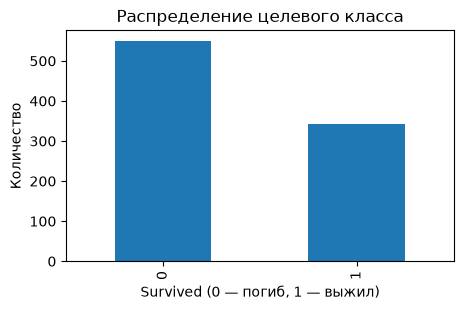

In [11]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

SEED = 42

paths = [Path('Titanic-Dataset.csv'), Path('../Titanic-Dataset.csv')]
csv_path = next((p for p in paths if p.is_file()), None)
if csv_path is None:
    raise FileNotFoundError('Не найден Titanic-Dataset.csv. Положите его рядом с ноутбуком.')
df = pd.read_csv(csv_path)
print('Размер:', df.shape)
display(df.head())
print('Типы столбцов:')
display(df.dtypes.to_frame('dtype'))
print('Пропуски:')
display(df.isna().sum().to_frame('missing'))
print('Полных дубликатов:', df.duplicated().sum())
print('Доля классов:')
display(df['Survived'].value_counts(normalize=True).sort_index().to_frame('share'))
fig, ax = plt.subplots(figsize=(5, 3))
df['Survived'].value_counts().sort_index().plot.bar(ax=ax)
ax.set(xlabel='Survived (0 — погиб, 1 — выжил)', ylabel='Количество', title='Распределение целевого класса')
plt.show()

**Вывод:** классы представлены неравномерно, поэтому основной показатель — F1 для выживших. `Age`, `Cabin`, `Embarked` содержат пропуски. `PassengerId`, полное `Name`, `Ticket` не используем как признаки: они могут идентифицировать пассажиров и способствовать запоминанию. Из `Name` извлекаем только распространённое обращение `Title` (`Mr`, `Mrs`, `Miss`, `Master`, остальные — `Other`); оно одинаково для многих пассажиров и не является идентификатором. `Cabin` исключаем из-за большого числа пропусков и риска идентификации. Для оставшихся признаков пропуски обрабатываем внутри обучаемого pipeline.


## 2. Разбиение и предобработка

In [12]:
df['Title'] = df['Name'].str.extract(r',\s*([^.]*)\.', expand=False).str.strip()
df['Title'] = df['Title'].where(df['Title'].isin(['Mr', 'Mrs', 'Miss', 'Master']), 'Other')
numeric_features = ['Age', 'Fare', 'SibSp', 'Parch']
categorical_features = ['Pclass', 'Sex', 'Embarked', 'Title']
features = numeric_features + categorical_features
X = df[features]
y = df['Survived']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED
)
print('Train:', len(X_train), 'Test:', len(X_test))
print('Доли выживших:', round(y_train.mean(), 3), round(y_test.mean(), 3))

def make_preprocessor(scale=False):
    num_steps = [('imputer', SimpleImputer(strategy='median'))]
    if scale:
        num_steps.append(('scaler', StandardScaler()))
    return ColumnTransformer([
        ('num', Pipeline(num_steps), numeric_features),
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
        ]), categorical_features)
    ], verbose_feature_names_out=False)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

Train: 712 Test: 179
Доли выживших: 0.383 0.385


### Первичный анализ связи признаков с выживанием


По полу


,Доля выживших,Пассажиров
Sex,,
female,0.743,253
male,0.185,459


По классу билета


,Доля выживших,Пассажиров
Pclass,,
1,0.649,171
2,0.447,150
3,0.243,391


По возрастной группе


,Доля выживших,Пассажиров
Age_group,,
0–12,0.600,55
13–18,0.415,53
19–35,0.377,284
36–60,0.407,167
61+,0.188,16


По обращению


,Доля выживших,Пассажиров
Title,,
Master,0.548,31
Miss,0.702,141
Mr,0.153,412
Mrs,0.785,107
Other,0.476,21


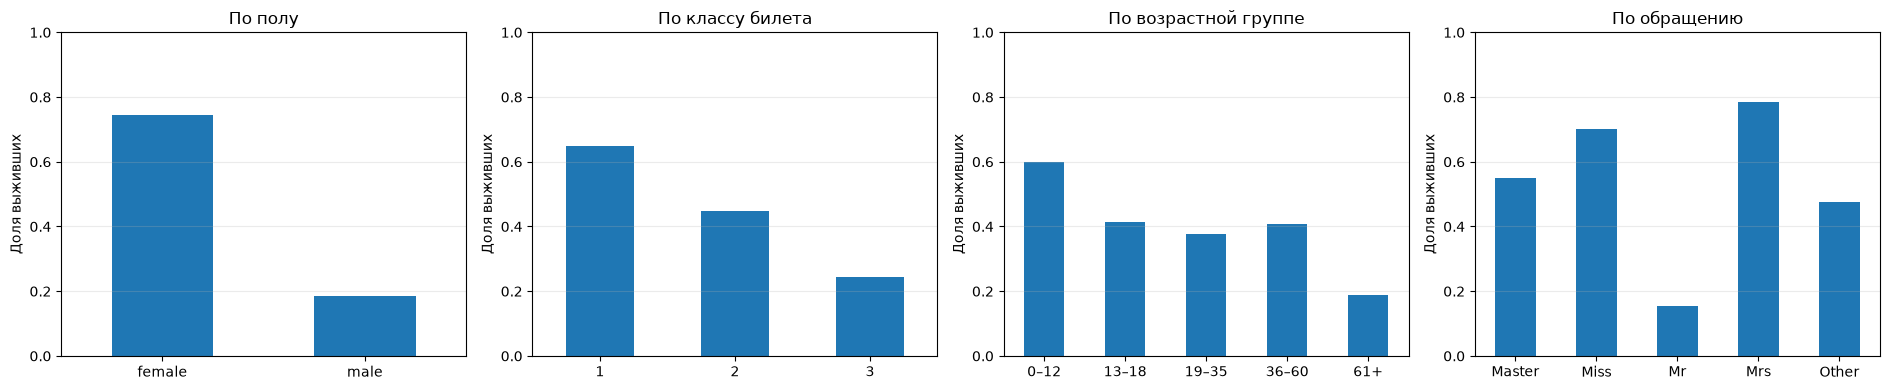

Возраст неизвестен у 137 пассажиров train; они не входят в возрастные группы.


In [13]:
# Смотрим связь признаков с выживанием только на train, не используя test.
eda = X_train.copy()
eda['Survived'] = y_train
eda['Age_group'] = pd.cut(
    eda['Age'], bins=[0, 12, 18, 35, 60, np.inf],
    labels=['0–12', '13–18', '19–35', '36–60', '61+'], include_lowest=True
)

fig, axes = plt.subplots(1, 4, figsize=(19, 4))
for ax, col, title in zip(
    axes,
    ['Sex', 'Pclass', 'Age_group', 'Title'],
    ['По полу', 'По классу билета', 'По возрастной группе', 'По обращению']
):
    summary = eda.groupby(col, observed=True)['Survived'].agg(['mean', 'count'])
    print(title)
    display(summary.rename(columns={'mean': 'Доля выживших', 'count': 'Пассажиров'}).round(3))
    summary['mean'].plot.bar(ax=ax, ylim=(0, 1), rot=0)
    ax.set_title(title)
    ax.set_xlabel('')
    ax.set_ylabel('Доля выживших')
    ax.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()
print('Возраст неизвестен у', eda['Age'].isna().sum(), 'пассажиров train; они не входят в возрастные группы.')


**Вывод по train:** женщины выживали чаще мужчин (74,3% против 18,5%); в 1-м классе доля выживших выше, чем во 2-м и 3-м (64,9%, 44,7%, 24,3%). Среди пассажиров с известным возрастом доля выживших в группе 0–12 лет составила 60%, а в группе 61+ — 18,8% (в последней всего 16 человек). По обращению доля выживших различается: `Mr` — 15,3%, `Miss` — 70,2%, `Mrs` — 78,5%, `Master` — 54,8%; группа `Other` мала (21 пассажир). Это наблюдаемые связи, а не доказательство причинности. Пассажиры с неизвестным возрастом не входят в возрастные группы; при обучении моделей пропуски обрабатываются внутри `Pipeline`.


**Обоснование:** для числовых пропусков используем медиану, для категорий — наиболее частое значение; категории, включая `Title`, переводим в one-hot. `Pclass` считаем категорией. `Title` извлечён из имени по фиксированному правилу, без целевой переменной; полное имя в модель не попадает. Все обучаемые операции находятся внутри `Pipeline`, поэтому параметры предобработки рассчитываются только на train соответствующего разбиения. Для SVM и KNN нужен `StandardScaler` (они зависят от расстояний/масштаба), для деревьев он не требуется.


## 3. Baseline и пять моделей

In [14]:
models = {
    'Dummy baseline': Pipeline([('preprocess', make_preprocessor()), ('model', DummyClassifier(strategy='most_frequent'))]),
    'Decision Tree': Pipeline([('preprocess', make_preprocessor()), ('model', DecisionTreeClassifier(max_depth=4, min_samples_leaf=5, random_state=SEED))]),
    'Random Forest': Pipeline([('preprocess', make_preprocessor()), ('model', RandomForestClassifier(n_estimators=200, min_samples_leaf=2, random_state=SEED, n_jobs=-1))]),
    'Gradient Boosting': Pipeline([('preprocess', make_preprocessor()), ('model', GradientBoostingClassifier(n_estimators=150, learning_rate=0.05, max_depth=2, random_state=SEED))]),
    'SVM': Pipeline([('preprocess', make_preprocessor(scale=True)), ('model', SVC(C=1.0, kernel='rbf'))]),
    'KNN': Pipeline([('preprocess', make_preprocessor(scale=True)), ('model', KNeighborsClassifier(n_neighbors=7, weights='distance'))]),
}
cv_rows = []
for name, model in models.items():
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring='f1', n_jobs=-1)
    cv_rows.append({'Модель': name, 'CV F1': scores.mean(), 'CV std': scores.std()})
cv_table = pd.DataFrame(cv_rows).sort_values('CV F1', ascending=False)
display(cv_table.round(3))
# Фиксируем лучшую реальную модель до просмотра результатов test.
best_name = cv_table.loc[cv_table['Модель'] != 'Dummy baseline', 'Модель'].iloc[0]
print('Лучшая модель по CV:', best_name)

,Модель,CV F1,CV std
2,Random Forest,0.753,0.037
4,SVM,0.751,0.033
3,Gradient Boosting,0.737,0.030
5,KNN,0.728,0.029
1,Decision Tree,0.715,0.029
0,Dummy baseline,0.000,0.000


Лучшая модель по CV: Random Forest


**Вывод:** сравниваем модели по среднему F1 на пяти обучающих фолдах. Лучшую модель для подробного анализа выбираем по CV F1.

## 4. Финальная проверка на общем test: метрики и confusion matrix

,Модель,Accuracy,Precision,Recall,F1,F1 > 0.70
4,SVM,0.844,0.847,0.725,0.781,True
5,KNN,0.827,0.806,0.725,0.763,True
2,Random Forest,0.827,0.828,0.696,0.756,True
3,Gradient Boosting,0.810,0.807,0.667,0.730,True
1,Decision Tree,0.799,0.811,0.623,0.705,True
0,Dummy baseline,0.615,0.000,0.000,0.000,False


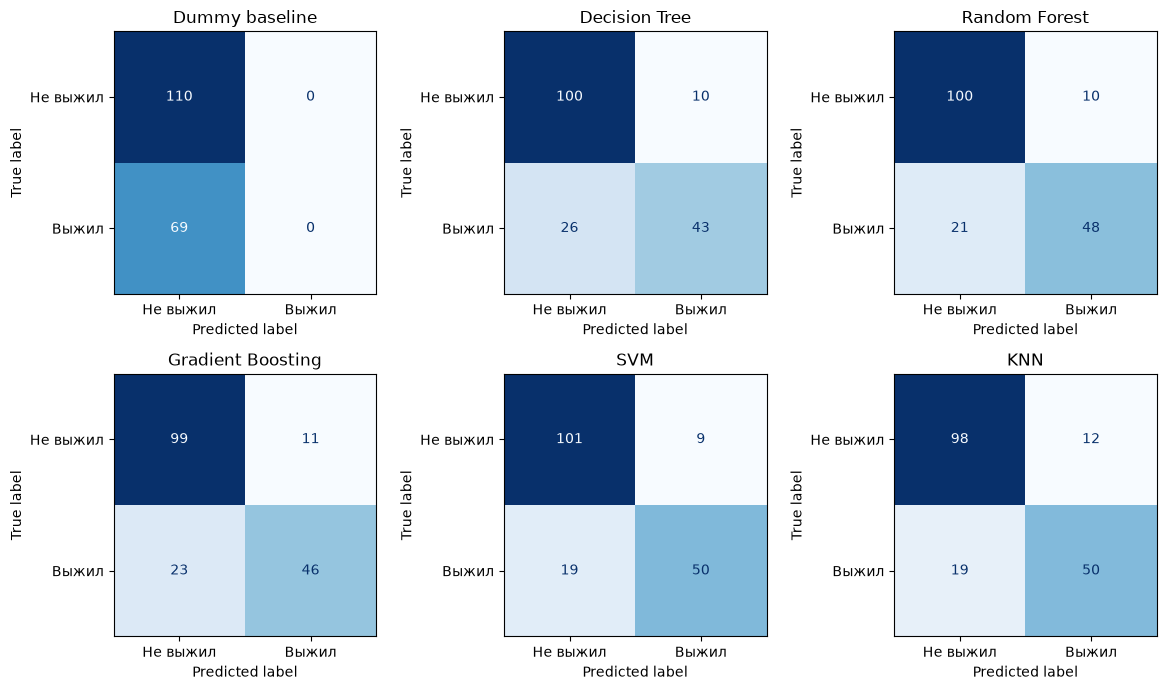

FP: прогноз «выжил», фактически погиб. FN: прогноз «погиб», фактически выжил.
Порог F1 > 0.70 преодолели: SVM, KNN, Random Forest, Gradient Boosting, Decision Tree


In [15]:
results = []
predictions = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    predictions[name] = pred
    results.append({
        'Модель': name,
        'Accuracy': accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred, zero_division=0),
        'Recall': recall_score(y_test, pred, zero_division=0),
        'F1': f1_score(y_test, pred, zero_division=0),
    })
result_table = pd.DataFrame(results).sort_values('F1', ascending=False)
result_table['F1 > 0.70'] = result_table['F1'] > 0.70
display(result_table.round(3))

fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for ax, (name, pred) in zip(axes.flat, predictions.items()):
    cm = confusion_matrix(y_test, pred, labels=[0, 1])
    ConfusionMatrixDisplay(cm, display_labels=['Не выжил', 'Выжил']).plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(name)
plt.tight_layout()
plt.show()
print('FP: прогноз «выжил», фактически погиб. FN: прогноз «погиб», фактически выжил.')
print('Порог F1 > 0.70 преодолели:', ', '.join(result_table.loc[(result_table['F1 > 0.70']) & (result_table['Модель'] != 'Dummy baseline'), 'Модель']) or 'нет')

**Итоги сравнения на test:** все пять моделей прошли порог **F1 > 0.70**: SVM — **0.781**, KNN — **0.763**, Random Forest — **0.756**, Gradient Boosting — **0.730**, Decision Tree — **0.705**. Baseline всегда предсказывает класс 0 и получил F1 = 0.000. По *обучающей* кросс-валидации лучшим был Random Forest (CV F1 = 0.753), поэтому именно он выбран для подробного анализа до тестовой оценки; SVM оказался лучшим по F1 на test, но менять выбор задним числом нельзя.

**Метрики:** Accuracy — доля правильных ответов; Precision — доля действительно выживших среди предсказанных выжившими; Recall — доля найденных выживших; F1 учитывает Precision и Recall вместе. **FP** — модель предсказала выживание пассажира, который погиб; **FN** — предсказала гибель пассажира, который выжил. Различия могут быть связаны с тем, как модели описывают закономерности: дерево — правилами, лес — ансамблем деревьев, бустинг — последовательными корректировками, SVM — разделяющей границей, KNN — похожими пассажирами.


## 5. Переобучение Decision Tree

In [16]:
tree = models['Decision Tree']
tree_train_acc = accuracy_score(y_train, tree.predict(X_train))
tree_test_acc = accuracy_score(y_test, tree.predict(X_test))
tree_train_f1 = f1_score(y_train, tree.predict(X_train))
tree_test_f1 = f1_score(y_test, tree.predict(X_test))
display(pd.DataFrame({'Train': [tree_train_acc, tree_train_f1], 'Test': [tree_test_acc, tree_test_f1]}, index=['Accuracy', 'F1']).round(3))
print('Разница F1 train - test:', round(tree_train_f1 - tree_test_f1, 3))

,Train,Test
Accuracy,0.844,0.799
F1,0.770,0.705


Разница F1 train - test: 0.065


**Вывод:** у Decision Tree **F1 на train = 0.770**, на **test = 0.705** (разница **0.065**). Это признак возможного переобучения: на обучающих данных дерево справляется лучше, чем на новых. Глубина (`max_depth=4`) и число объектов в листе (`min_samples_leaf=5`) ограничены, чтобы уменьшить этот риск. По одному разбиению нельзя утверждать, что переобучение доказано однозначно.


## 6. Feature Importance трёх моделей деревьев

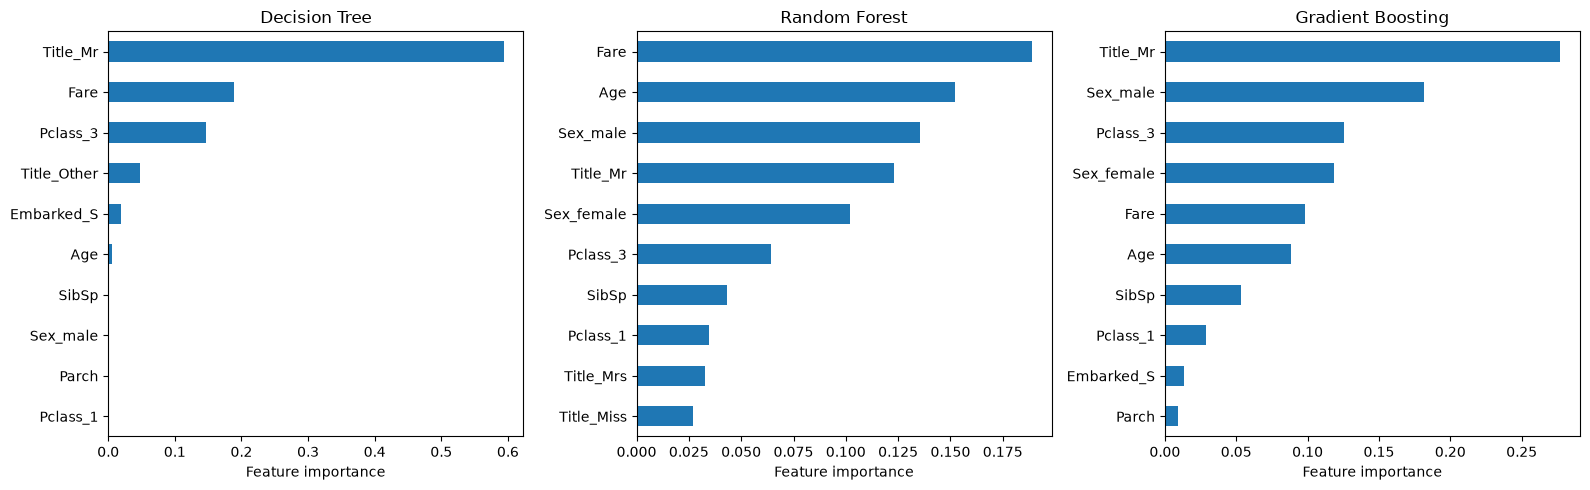

,Модель,Топ-3 признака
0,Decision Tree,"Title_Mr, Fare, Pclass_3"
1,Random Forest,"Fare, Age, Sex_male"
2,Gradient Boosting,"Title_Mr, Sex_male, Pclass_3"


In [17]:
importance_rows = []
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, name in zip(axes, ['Decision Tree', 'Random Forest', 'Gradient Boosting']):
    pipeline = models[name]
    names = pipeline.named_steps['preprocess'].get_feature_names_out()
    values = pipeline.named_steps['model'].feature_importances_
    imp = pd.Series(values, index=names).sort_values(ascending=False)
    imp.head(10).sort_values().plot.barh(ax=ax)
    ax.set_title(name)
    ax.set_xlabel('Feature importance')
    importance_rows.append({'Модель': name, 'Топ-3 признака': ', '.join(imp.head(3).index)})
plt.tight_layout()
plt.show()
display(pd.DataFrame(importance_rows))

**Сравнение важности признаков в полученных результатах:**
- **Decision Tree:** `Title_Mr`, `Fare`, `Pclass_3`.
- **Random Forest:** `Fare`, `Age`, `Sex_male`.
- **Gradient Boosting:** `Title_Mr`, `Sex_male`, `Pclass_3`.

У дерева и бустинга выделяется обращение `Mr`, у леса — стоимость билета и возраст. Пол и класс также важны. Различия в долях выживших по полу, классу, возрасту и обращению были видны при первичном анализе train. Отдельного анализа связи стоимости билета с выживанием мы не проводили. Важности могут различаться из-за устройства моделей и корреляции признаков. **Важность признака для прогноза не означает, что он стал причиной выживания.**


## 7. Анализ ошибок лучшей по CV модели

In [18]:
pred = predictions[best_name]
cm = confusion_matrix(y_test, pred, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()
print(f'{best_name}: TN={tn}, FP={fp}, FN={fn}, TP={tp}')
print('Чаще встречаются:', 'FN' if fn > fp else ('FP' if fp > fn else 'FP и FN поровну'))

analysis = X_test.copy()
analysis['Факт'] = y_test.to_numpy()
analysis['Прогноз'] = pred
analysis['Ошибка'] = analysis['Факт'] != analysis['Прогноз']
for group in ['Sex', 'Pclass']:
    print(f'Доля ошибок по {group}:')
    display(analysis.groupby(group)['Ошибка'].agg(['count', 'mean']).rename(columns={'mean': 'error_rate'}).round(3))
print('Доля ошибок по возрастным группам:')
analysis['Age_group'] = pd.cut(analysis['Age'], bins=[0, 12, 18, 35, 60, np.inf], include_lowest=True)
display(analysis.groupby('Age_group', observed=True)['Ошибка'].agg(['count', 'mean']).rename(columns={'mean': 'error_rate'}).round(3))
print('Примеры неверных прогнозов (без идентификаторов):')
display(analysis.loc[analysis['Ошибка'], features + ['Факт', 'Прогноз']].head(8))

Random Forest: TN=100, FP=10, FN=21, TP=48
Чаще встречаются: FN
Доля ошибок по Sex:


,count,error_rate
Sex,,
female,61,0.197
male,118,0.161


Доля ошибок по Pclass:


,count,error_rate
Pclass,,
1,45,0.244
2,34,0.088
3,100,0.170


Доля ошибок по возрастным группам:


,count,error_rate
Age_group,,
"(-0.001, 12.0]",14,0.071
"(12.0, 18.0]",17,0.059
"(18.0, 35.0]",74,0.176
"(35.0, 60.0]",28,0.214
"(60.0, inf]",6,0.333


Примеры неверных прогнозов (без идентификаторов):


,Age,Fare,SibSp,Parch,Pclass,Sex,Embarked,Title,Факт,Прогноз
553,22.0,7.2250,0,0,3,male,C,Mr,1,0
559,36.0,17.4000,1,0,3,female,S,Mrs,1,0
216,27.0,7.9250,0,0,3,female,S,Miss,1,0
279,35.0,20.2500,1,1,3,female,S,Mrs,1,0
712,48.0,52.0000,1,0,1,male,S,Mr,1,0
455,29.0,7.8958,0,0,3,male,C,Mr,1,0
745,70.0,71.0000,1,1,1,male,S,Other,0,1
297,2.0,151.5500,1,2,1,female,S,Miss,0,1


**Анализ ошибок:** у выбранного по CV Random Forest **FP = 10, FN = 21**: модель чаще ошибочно предсказывала гибель реально выживших. На этом test доля ошибок выше у пассажиров **1-го класса (24,4%)**, чем 2-го (8,8%) и 3-го (17,0%); среди возрастных групп — **старше 60 лет (33,3%)** и **35–60 лет (21,4%)**. В группе старше 60 лет всего 6 пассажиров, поэтому доля нестабильна.

**Три конкретные ошибки из таблицы выше (индексы строк исходного набора):**
- **553:** мужчина, 22 года, 3-й класс, обращение `Mr`. Модель предсказала гибель (**0**), но он выжил (**1**). Возможно, сочетание пола и класса делало такой исход менее типичным для модели.
- **559:** женщина, 36 лет, 3-й класс, обращение `Mrs`. Модель предсказала гибель (**0**), но она выжила (**1**). Возможно, другие признаки (класс, цена билета, семейные связи) перевесили обращение.
- **745:** мужчина, 70 лет, 1-й класс, обращение `Other`. Модель предсказала выживание (**1**), но он погиб (**0**). Возможно, модель переоценила вероятность выживания пассажира 1-го класса.

Это предположения, а не известные причины отдельных исходов: данных об обстоятельствах эвакуации нет. `PassengerId`, полное `Name`, `Ticket`, `Cabin` не подавались в модель; `Title` содержит только одно из пяти общих обращений и не идентифицирует человека. Выбор модели сделан по CV на train, а не по test.


## 8. Итог

In [19]:
print(f'Лучшая по train-CV модель: {best_name}.')
print('Её итоговый F1 на test:', round(f1_score(y_test, predictions[best_name]), 3))
print('Установленный порог F1 > 0.70:', 'пройден' if f1_score(y_test, predictions[best_name]) > 0.70 else 'не пройден')
print('Финальное сравнение всех моделей:')
display(result_table.round(3))

Лучшая по train-CV модель: Random Forest.
Её итоговый F1 на test: 0.756
Установленный порог F1 > 0.70: пройден
Финальное сравнение всех моделей:


,Модель,Accuracy,Precision,Recall,F1,F1 > 0.70
4,SVM,0.844,0.847,0.725,0.781,True
5,KNN,0.827,0.806,0.725,0.763,True
2,Random Forest,0.827,0.828,0.696,0.756,True
3,Gradient Boosting,0.810,0.807,0.667,0.730,True
1,Decision Tree,0.799,0.811,0.623,0.705,True
0,Dummy baseline,0.615,0.000,0.000,0.000,False
